# Methane surge reconstruction, 2019–2022
All anomalies use 2019. He curves are digitized central estimates, **not independent reproductions of the inversion**. The NOAA common-burden calculation is a sensitivity experiment, not a native reconstruction. See `docs/derivations/`, `data/README.md`, and the report for assumptions and missing materials.

In [1]:
from pathlib import Path
import tomllib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "config.toml").exists():
    root = root.parent
config = tomllib.loads((root / "config.toml").read_text())
processed = root / config["paths"]["processed"]
figures = root / config["paths"]["figures"]
figures.mkdir(exist_ok=True)
h = xr.load_dataset(processed / "he_digitized.nc")
a = xr.load_dataset(processed / "published_annual.nc")
n = xr.load_dataset(processed / "noaa.nc")
p = xr.load_dataset(processed / "peng_inversion.nc")
ps = pd.read_csv(processed / "peng_source_data.csv").set_index("component")
s = pd.read_csv(processed / "stevenson_4mm.csv").set_index("region")
c = xr.load_dataset(processed / "ciais.nc")
qe = pd.read_csv(processed / "qu2022_sensitivity.csv")
qr = pd.read_csv(processed / "qu2022_regional.csv")
benchmark = config["analysis"]["oh_lifetime_benchmark"]
years = h.year.values
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 180, "pdf.fonttype": 42})

def save(fig, name):
    fig.savefig(figures / (name + ".pdf"), bbox_inches="tight")
    fig.savefig(figures / (name + ".png"), bbox_inches="tight")
    plt.show()

def axes_year(ax):
    ax.set_xticks(years)
    ax.axhline(0, color="0.7", lw=.7)
    ax.set_xlabel("Year")


## He Figure 1: concentration change, restricted to the requested period
Original central curves digitized from the public raster. Updated NOAA values provide a separate comparison. Dashed curves are digitized published counterfactuals, not fitted trajectories.

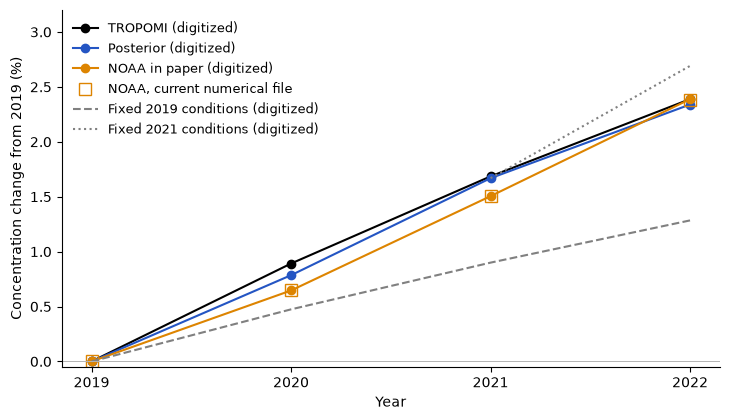

In [2]:
fig, ax = plt.subplots(figsize=(7.4, 4.3))
for name, label, color in [("tropomi", "TROPOMI (digitized)", "k"),
                           ("posterior", "Posterior (digitized)", "#2455c3"),
                           ("noaa_published", "NOAA in paper (digitized)", "#dd8400")]:
    ax.plot(years, h[name + "_percent"], "o-", color=color, label=label)
ax.plot(years, n.concentration_anomaly_percent, "s", mfc="none", ms=8, color="#dd8400", label="NOAA, current numerical file")
ax.plot(years, h.constant_2019_percent, "--", color=".5", label="Fixed 2019 conditions (digitized)")
ax.plot(years, h.constant_2021_percent, ":", color=".5", label="Fixed 2021 conditions (digitized)")
axes_year(ax)
ax.set_ylabel("Concentration change from 2019 (%)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_ylim(-.05, 3.2)
fig.tight_layout()
save(fig, "he_figure1")

## He Figure 2: re-expressing all four panels relative to 2019
Panel B subtracts the 2019 relaxation contribution; it therefore displays a negative relaxation anomaly. The positive contributions are emissions and OH forcing. Source uncertainty envelopes cannot be recovered from the numerical data and are omitted.

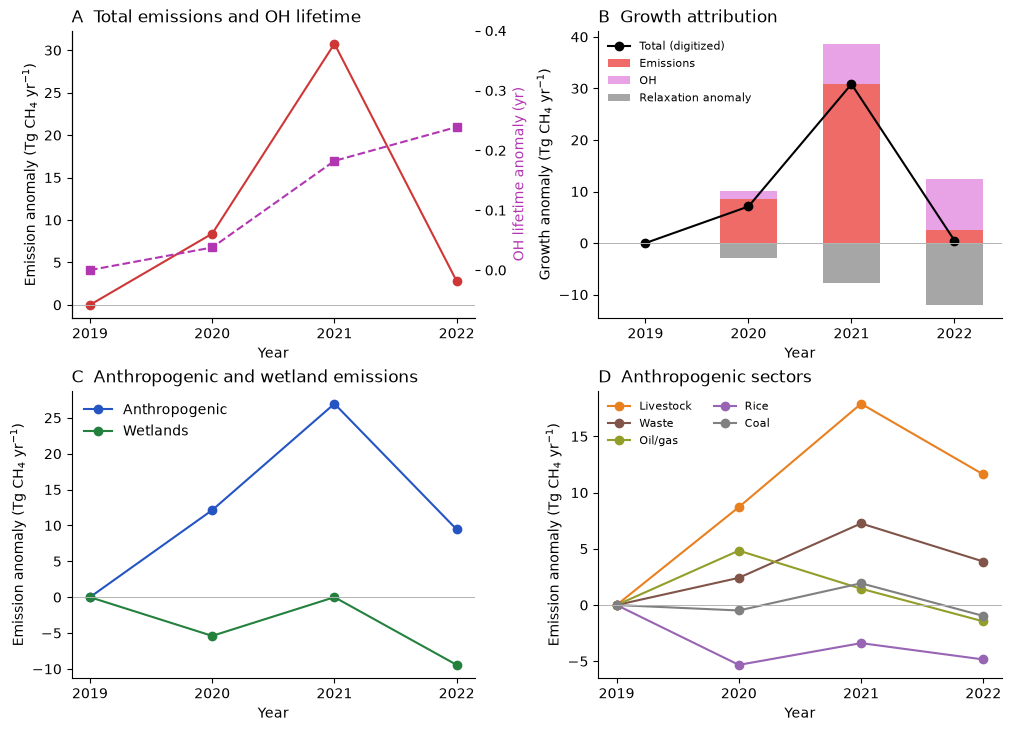

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7.2), constrained_layout=True)
ax = axs[0, 0]
ax.plot(years, h.emission_forcing, "o-", color="#cf3737", label="Emissions")
ax.set_ylabel("Emission anomaly (Tg CH$_4$ yr$^{-1}$)")
right = ax.twinx()
right.plot(years, h.oh_lifetime - h.oh_lifetime.sel(year=2019), "s--", color="#b236b2", label="OH lifetime")
right.set_ylabel("OH lifetime anomaly (yr)", color="#b236b2")
right.set_ylim(-.08, .4)
ax.set_title("A  Total emissions and OH lifetime", loc="left")
ax = axs[0, 1]
ax.bar(years, h.emission_forcing_bar, width=.56, color="#ef6b67", label="Emissions")
ax.bar(years, h.oh_forcing, bottom=h.emission_forcing_bar, width=.56, color="#e8a3e6", label="OH")
ax.bar(years, h.relaxation_anomaly, width=.56, color=".65", label="Relaxation anomaly")
ax.plot(years, h.growth_anomaly, "ko-", label="Total (digitized)")
ax.set_ylabel("Growth anomaly (Tg CH$_4$ yr$^{-1}$)")
ax.set_title("B  Growth attribution", loc="left")
ax.legend(frameon=False, fontsize=8)
ax = axs[1, 0]
for name, label, color in [("anthropogenic", "Anthropogenic", "#2455c3"), ("wetland", "Wetlands", "#24813d")]:
    ax.plot(years, h[name] - h[name].sel(year=2019), "o-", label=label, color=color)
ax.set_ylabel("Emission anomaly (Tg CH$_4$ yr$^{-1}$)")
ax.set_title("C  Anthropogenic and wetland emissions", loc="left")
ax.legend(frameon=False)
ax = axs[1, 1]
for name, label, color in [("livestock", "Livestock", "#e98020"), ("waste", "Waste", "#805449"), ("oil_gas", "Oil/gas", "#929e29"), ("rice", "Rice", "#9864b4"), ("coal", "Coal", ".5")]:
    ax.plot(years, h[name] - h[name].sel(year=2019), "o-", label=label, color=color)
ax.set_title("D  Anthropogenic sectors", loc="left")
ax.set_ylabel("Emission anomaly (Tg CH$_4$ yr$^{-1}$)")
ax.legend(frameon=False, fontsize=8, ncol=2)
for ax in axs.flat: axes_year(ax)
save(fig, "he_figure2")

## Comparing emission anomalies and OH terms
Every study uses its own 2019 baseline. Qu (2022) supplies native burden; Qu (2024) requires the labeled common-burden approximation. Ciais central emission markers are digitized. Peng retains its reported calendar-year attribution.

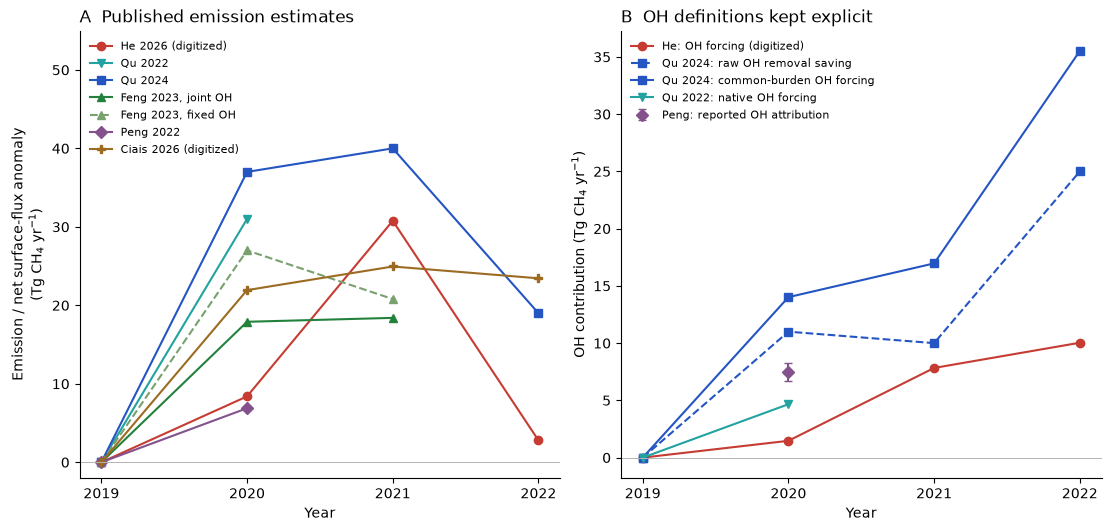

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2), constrained_layout=True)
ax = axs[0]
ax.plot(years, h.emission_forcing, "o-", color="#c63c32", label="He 2026 (digitized)")
for study, label, color, style in [("Qu2022", "Qu 2022", "#22a2a0", "v-"), ("Qu2024", "Qu 2024", "#2455c3", "s-"), ("Feng2023_joint", "Feng 2023, joint OH", "#24813d", "^-"), ("Feng2023_fixed", "Feng 2023, fixed OH", "#79a16e", "^--")]:
    ax.plot(years, a.emission_forcing.sel(study=study), style, color=color, label=label)
ax.plot([2019,2020], [0,ps.loc["inversion_net_flux","global"]], "D-", color="#83528c", label="Peng 2022")
ax.plot(years, c.emission_forcing, "P-", color="#9c6b22", label="Ciais 2026 (digitized)")
ax.set_ylabel("Emission / net surface-flux anomaly\n(Tg CH$_4$ yr$^{-1}$)")
ax.set_title("A  Published emission estimates", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_ylim(-2, 55)
ax = axs[1]
q = a.sel(study="Qu2024")
ax.plot(years, h.oh_forcing, "o-", color="#c63c32", label="He: OH forcing (digitized)")
ax.plot(years, q.oh_sink_saving, "s--", color="#2455c3", label="Qu 2024: raw OH removal saving")
ax.plot(years, q.oh_forcing_common_burden, "s-", color="#2455c3", label="Qu 2024: common-burden OH forcing")
ax.plot(years, a.oh_forcing_native.sel(study="Qu2022"), "v-", color="#22a2a0", label="Qu 2022: native OH forcing")
ax.errorbar([2020], [7.5], yerr=[.8], fmt="D", color="#83528c", capsize=3, label="Peng: reported OH attribution")
ax.set_ylabel("OH contribution (Tg CH$_4$ yr$^{-1}$)")
ax.set_title("B  OH definitions kept explicit", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left")
for ax in axs: axes_year(ax)
save(fig, "flux_comparison")

## Quantifying the adjustment and the baseline mismatch
The left panel is a lifetime sensitivity experiment with NOAA annual surface means as a burden proxy. The right panel compares growth anomalies and states the distinct absolute 2019 growth values in its legend.

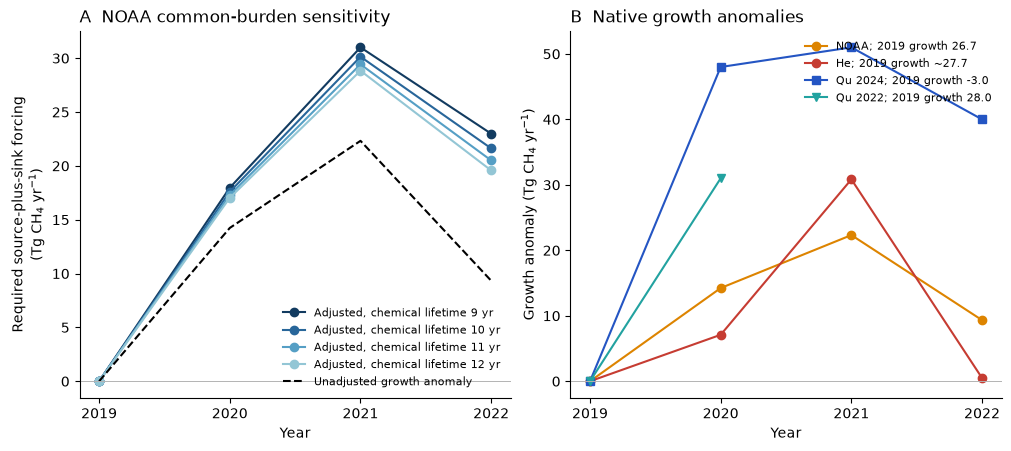

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
ax = axs[0]
for tau, color in zip([9,10,11,12], ["#123b60", "#28669a", "#559fc5", "#93c6d5"]):
    ax.plot(years, n.required_forcing.sel(chemical_lifetime=tau), "o-", color=color, label=f"Adjusted, chemical lifetime {tau} yr")
ax.plot(years, n.growth_anomaly, "k--", label="Unadjusted growth anomaly")
ax.set_ylabel("Required source-plus-sink forcing\n(Tg CH$_4$ yr$^{-1}$)")
ax.set_title("A  NOAA common-burden sensitivity", loc="left")
ax.legend(frameon=False, fontsize=8)
ax = axs[1]
# Display baseline values as a comparison table, keeping every plotted curve anomalous.
ax.plot(years, n.growth_anomaly, "o-", color="#dd8400", label=f"NOAA; 2019 growth {float(n.growth_mass.sel(year=2019)):.1f}")
ax.plot(years, h.growth_anomaly, "o-", color="#c63c32", label=f"He; 2019 growth ~{float(h.growth.sel(year=2019)):.1f}")
ax.plot(years, q.growth_anomaly, "s-", color="#2455c3", label=f"Qu 2024; 2019 growth {float(q.growth.sel(year=2019)):.1f}")
ax.plot(years, a.growth_anomaly.sel(study="Qu2022"), "v-", color="#22a2a0", label="Qu 2022; 2019 growth 28.0")
ax.set_title("B  Native growth anomalies", loc="left")
ax.set_ylabel("Growth anomaly (Tg CH$_4$ yr$^{-1}$)")
ax.legend(frameon=False, fontsize=8)
for ax in axs: axes_year(ax)
save(fig, "adjustment_and_baseline")

## Regional evidence with different meanings
Peng provides regional methane flux changes. Stevenson provides global methane-growth responses to emissions of precursors in each region. These are not interchangeable regional methane budgets.

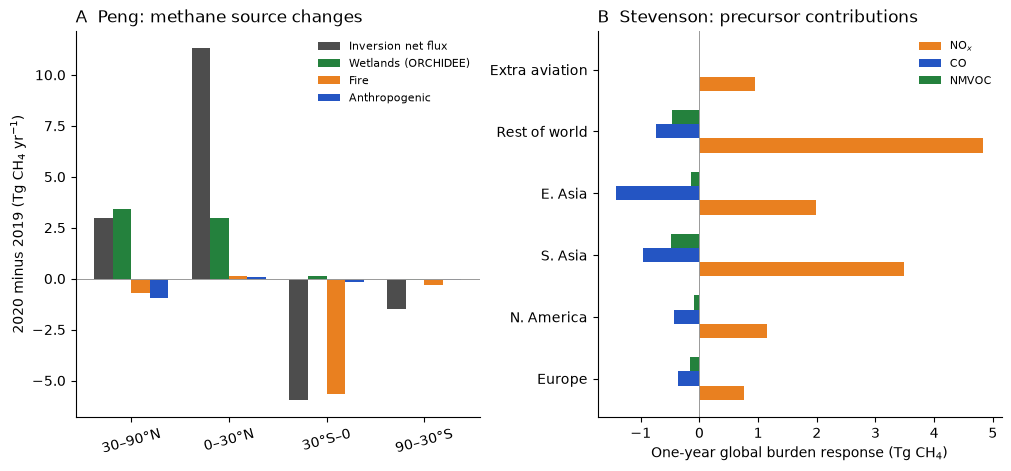

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True)
ax = axs[0]
regions = ["30N_90N", "0_30N", "30S_0", "90S_30S"]
x = np.arange(4)
for i, (key, label, color) in enumerate([("inversion_net_flux", "Inversion net flux", ".3"), ("ORCHIDEE", "Wetlands (ORCHIDEE)", "#24813d"), ("fire", "Fire", "#e98020"), ("anthropogenic", "Anthropogenic", "#2455c3")]):
    ax.bar(x + (i-1.5)*.19, ps.loc[key, regions].astype(float), width=.19, label=label, color=color)
ax.set_xticks(x, ["30–90°N", "0–30°N", "30°S–0", "90–30°S"], rotation=15)
ax.axhline(0, color=".6", lw=.7)
ax.set_ylabel("2020 minus 2019 (Tg CH$_4$ yr$^{-1}$)")
ax.set_title("A  Peng: methane source changes", loc="left")
ax.legend(frameon=False, fontsize=8)
ax = axs[1]
regions = ["Europe", "N America", "S Asia", "E Asia", "ROW", "Aviation (extra)"]
y = np.arange(len(regions))
for i, (name, label, color) in enumerate([("NOx", "NO$_x$", "#e98020"), ("CO", "CO", "#2455c3"), ("NMVOC", "NMVOC", "#24813d")]):
    ax.barh(y + (i-1)*.23, s.loc[regions, name].fillna(0)*2.77, height=.23, color=color, label=label)
ax.set_yticks(y, ["Europe", "N. America", "S. Asia", "E. Asia", "Rest of world", "Extra aviation"])
ax.axvline(0, color=".6", lw=.7)
ax.set_xlabel("One-year global burden response (Tg CH$_4$)")
ax.set_title("B  Stevenson: precursor contributions", loc="left")
ax.legend(frameon=False, fontsize=8)
save(fig, "regional_evidence")

## Peng archived gridded flux anomaly
Day-weighted annual mean net surface-flux rates. This is a reproducible calculation from posterior output, not a new inversion. No regional OH attribution is inferred.

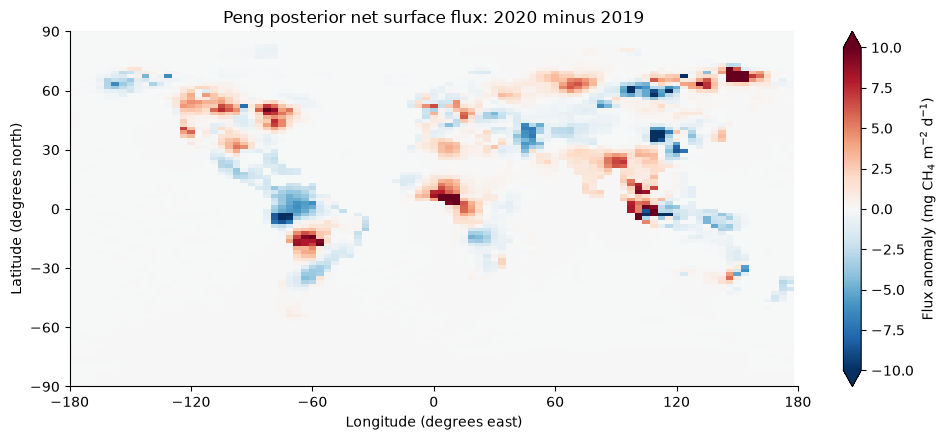

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
mesh = ax.pcolormesh(p.lon, p.lat, p.net_flux_anomaly.sel(year=2020), cmap="RdBu_r", vmin=-10, vmax=10, shading="auto", rasterized=True)
ax.set(xlim=(-180,180), ylim=(-90,90), xlabel="Longitude (degrees east)", ylabel="Latitude (degrees north)", title="Peng posterior net surface flux: 2020 minus 2019")
ax.set_xticks(np.arange(-180,181,60))
ax.set_yticks(np.arange(-90,91,30))
fig.colorbar(mesh, ax=ax, label="Flux anomaly (mg CH$_4$ m$^{-2}$ d$^{-1}$)", extend="both")
fig.tight_layout()
save(fig, "peng_flux_map")

## Ciais signed removal anomalies and a conditional adjustment
Annual central circles in Figure S3 are rebased from their published 2010 reference to 2019. Positive values mean reduced removal. The right panel assumes the NOAA burden proxy and an 11.1-year 2019 OH lifetime, with 9–12-year sensitivity shading. Shading is not posterior uncertainty; both sides contain digitization error.

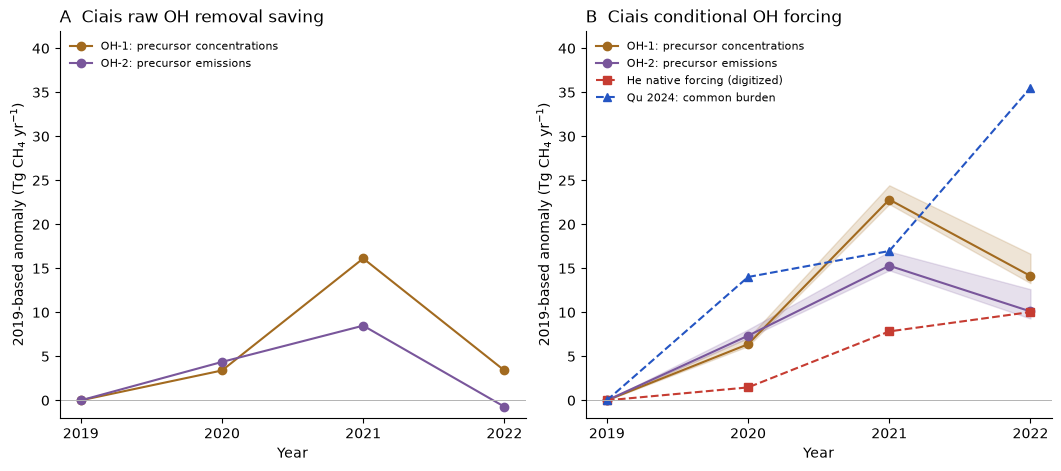

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
for field, label, color in [("OH1", "OH-1: precursor concentrations", "#a26a1f"),
                             ("OH2", "OH-2: precursor emissions", "#79569b")]:
    axs[0].plot(years, c.oh_sink_saving.sel(OH_field=field), "o-", color=color, label=label)
    f = c.oh_forcing_common_burden.sel(OH_field=field)
    axs[1].plot(years, f.sel(OH_lifetime=benchmark), "o-", color=color, label=label)
    axs[1].fill_between(years, f.min("OH_lifetime"), f.max("OH_lifetime"), color=color, alpha=.18)
axs[1].plot(years, h.oh_forcing, "s--", color="#c63c32", label="He native forcing (digitized)")
axs[1].plot(years, a.oh_forcing_common_burden.sel(study="Qu2024"), "^--", color="#2455c3", label="Qu 2024: common burden")
axs[0].set_title("A  Ciais raw OH removal saving", loc="left")
axs[1].set_title("B  Ciais conditional OH forcing", loc="left")
for ax in axs:
    axes_year(ax)
    ax.set_ylabel("2019-based anomaly (Tg CH$_4$ yr$^{-1}$)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.set_ylim(-2, 42)
save(fig, "ciais_adjustment")

## Qu (2022) native forcing sensitivity and regional emission changes
All quantities compare 2020 with 2019. Left: total forcing and emissions from the main text and Supplement Table S1; OH is their difference, retaining the rounded inputs. Right: Table 2 base regional anomalies and ensemble means with one-standard-deviation spread. No new flux inversion is performed.

<>:6: SyntaxWarning: invalid escape sequence '\g'
<>:6: SyntaxWarning: invalid escape sequence '\g'
<>:6: SyntaxWarning: invalid escape sequence '\g'
<>:6: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_3958701/3616877298.py:6: SyntaxWarning: invalid escape sequence '\g'
  axs[0].set_xticks(x, ["Base", "$\gamma$ 0.1", "$\gamma$ 1", "Anth. 30%", "Anth. 60%", "OH 5%", "OH 20%", "Wet. 20%", "Wet. 60%"], rotation=50, ha="right")
/tmp/ipykernel_3958701/3616877298.py:6: SyntaxWarning: invalid escape sequence '\g'
  axs[0].set_xticks(x, ["Base", "$\gamma$ 0.1", "$\gamma$ 1", "Anth. 30%", "Anth. 60%", "OH 5%", "OH 20%", "Wet. 20%", "Wet. 60%"], rotation=50, ha="right")


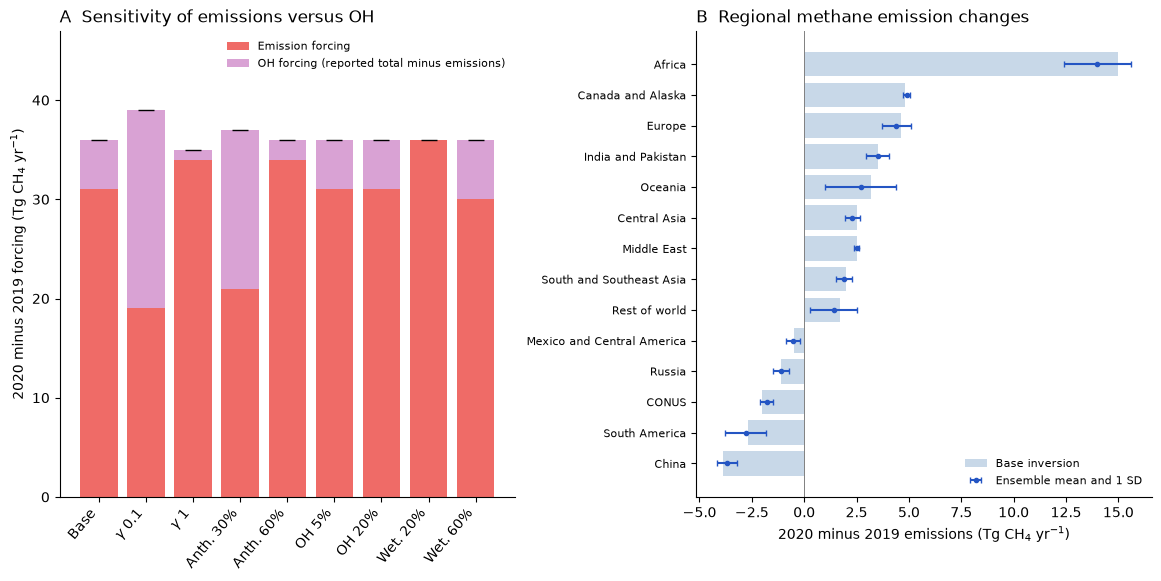

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 5.7), constrained_layout=True)
x = np.arange(len(qe))
axs[0].bar(x, qe.emission_change, color="#ef6b67", label="Emission forcing")
axs[0].bar(x, qe.oh_forcing_reported, bottom=qe.emission_change, color="#d9a2d4", label="OH forcing (reported total minus emissions)")
axs[0].plot(x, qe.total_forcing, "k_", ms=11)
axs[0].set_xticks(x, ["Base", "$\gamma$ 0.1", "$\gamma$ 1", "Anth. 30%", "Anth. 60%", "OH 5%", "OH 20%", "Wet. 20%", "Wet. 60%"], rotation=50, ha="right")
axs[0].set_ylabel("2020 minus 2019 forcing (Tg CH$_4$ yr$^{-1}$)")
axs[0].set_title("A  Sensitivity of emissions versus OH", loc="left")
axs[0].set_ylim(0, 47)
axs[0].legend(frameon=False, fontsize=8)
r = qr.sort_values("base_anomaly")
y = np.arange(len(r))
axs[1].barh(y, r.base_anomaly, color="#c8d8e8", label="Base inversion")
axs[1].errorbar(r.ensemble_mean_anomaly, y, xerr=r.ensemble_sd_anomaly, fmt="o", color="#2455c3", ms=3, capsize=2, label="Ensemble mean and 1 SD")
axs[1].set_yticks(y, r.region, fontsize=8)
axs[1].axvline(0, color=".5", lw=.7)
axs[1].set_xlabel("2020 minus 2019 emissions (Tg CH$_4$ yr$^{-1}$)")
axs[1].set_title("B  Regional methane emission changes", loc="left")
axs[1].legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "qu2022_sensitivity")